# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Нафранович Д.И. 
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->
<style>
@media print {
  @page { margin: 12mm; }

  .jp-Cell { padding: 1px 0 !important; }

  .jp-RenderedHTMLCommon {
    font-size: 10pt !important;
    line-height: 1.22 !important;
  }

  .jp-RenderedHTMLCommon h1 {
    font-size: 16pt !important;
    margin: 0.4em 0 0.3em !important;
  }

  .jp-RenderedHTMLCommon h2 {
    font-size: 13pt !important;
    margin: 0.5em 0 0.25em !important;
  }

  .jp-RenderedHTMLCommon h3 {
    font-size: 11pt !important;
    margin: 0.45em 0 0.2em !important;
  }

  .jp-RenderedHTMLCommon p,
  .jp-RenderedHTMLCommon ol {
    margin: 0.3em 0 !important;
  }

  .jp-RenderedHTMLCommon li {
    margin: 0.12em 0 !important;
  }

  .jp-RenderedHTMLCommon table {
    font-size: 9pt !important;
  }

  .jp-RenderedHTMLCommon table th,
  .jp-RenderedHTMLCommon table td {
    padding: 3px 5px !important;
  }

  .jp-RenderedImage img {
    max-width: 90% !important;
    max-height: 275px !important;
    width: auto !important;
    height: auto !important;
  }

  .jp-RenderedMarkdown p,
  .jp-RenderedMarkdown li {
    text-align: justify !important;
  }
  
  .jp-OutputArea-output pre {
    font-size: 9pt !important;
    line-height: 1.15 !important;
  }
}
</style>

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

clean = pd.read_parquet("clean_data.parquet")

In [16]:
REPORT_DEBUG = False

campaign_list = pd.read_csv(
    "campaign_list.csv",
    dtype={"client_id": "string", "group": "string"},
)

cleaning_log = pd.read_csv("cleaning_log.csv")

report_transactions = pd.read_parquet(
    "report_transactions_first.parquet"
)

In [17]:
report_selected_clients = clean.loc[
    clean["group"].notna(), ["client_id", "group"]
].copy()

report_selected_clients["client_id"] = (
    report_selected_clients["client_id"].astype("string")
)
report_selected_clients["group"] = (
    report_selected_clients["group"].astype("string")
)

report_campaign_check = report_selected_clients.merge(
    campaign_list[["client_id", "group"]],
    on="client_id",
    how="outer",
    suffixes=("_clean", "_list"),
    indicator=True,
    validate="one_to_one",
)

report_groups_match = (
    report_campaign_check["_merge"].eq("both")
    & report_campaign_check["group_clean"]
        .eq(report_campaign_check["group_list"])
        .fillna(False)
).all()

if not report_groups_match:
    raise ValueError(
        "Группы или клиенты в clean и campaign_list не совпадают."
    )

if not clean["client_id"].is_unique:
    raise ValueError("В clean есть повторные client_id.")

report_period = report_transactions.loc[
    report_transactions["client_id"].isin(clean["client_id"])
    & (report_transactions["txn_datetime"] >= "2024-01-01")
    & (report_transactions["txn_datetime"] < "2025-07-01")
].copy()

report_successful = report_period.loc[
    report_period["status"].eq("успешно")
].copy()

report_selected_ops = report_successful.loc[
    report_successful["channel"].isin(["Карта", "Токен"])
].copy()

report_base_ops = report_selected_ops.loc[
    (report_selected_ops["txn_datetime"] >= "2024-01-01")
    & (report_selected_ops["txn_datetime"] < "2025-01-01")
]

report_base_h1_ops = report_selected_ops.loc[
    (report_selected_ops["txn_datetime"] >= "2024-01-01")
    & (report_selected_ops["txn_datetime"] < "2024-07-01")
]

report_current_ops = report_selected_ops.loc[
    (report_selected_ops["txn_datetime"] >= "2025-01-01")
    & (report_selected_ops["txn_datetime"] < "2025-07-01")
]

report_base_counts = report_base_ops.groupby("client_id").size()
report_current_counts = report_current_ops.groupby("client_id").size()

report_base_by_client = (
    clean["client_id"].map(report_base_counts).fillna(0).astype(int)
)

report_current_by_client = (
    clean["client_id"].map(report_current_counts).fillna(0).astype(int)
)

report_base_differences = (
    report_base_by_client != clean["operations_2024"]
).sum()

report_current_differences = (
    report_current_by_client != clean["operations_2025_h1"]
).sum()

if report_base_differences or report_current_differences:
    raise ValueError(
        "Операции не совпадают с клиентскими метриками в clean."
    )

report_mcc_comparable = (
    report_selected_ops["category"].notna()
    & report_selected_ops["mcc_reference_category"].notna()
)

report_mcc_disagreement = (
    report_mcc_comparable
    & report_selected_ops["category"]
        .ne(report_selected_ops["mcc_reference_category"])
        .fillna(False)
)

if REPORT_DEBUG:
    print("Клиентов когорты:", len(clean))
    print("Группы и клиенты совпадают с campaign_list:", report_groups_match)
    print("Выбранных операций за оба периода:", len(report_selected_ops))
    print("Операций за 2024 год:", len(report_base_ops))
    print("Операций за январь–июнь 2024:", len(report_base_h1_ops))
    print("Операций за январь–июнь 2025:", len(report_current_ops))
    print("Расхождений с метриками клиентов:",
          report_base_differences, "и", report_current_differences)
    print("Расхождений с эмпирической категорией MCC:",
          report_mcc_disagreement.sum())

## 1. Главное

<!-- 3–5 выводов с числами. Пишется последним, читается первым.
     Каждый вывод — утверждение, а не тема. Не «анализ активности»,
     а «активность упала на X% у группы Y за счёт Z». -->

1. В сопоставимой когорте из 5502 клиентов средняя активность снизилась с 4,086 операции на клиента в месяц за 2024 год до 3,496 за первое полугодие 2025 года, то есть на 14,45% за счет других более удобных способов оплаты. При сравнении одинаковых полугодий снижение сохранилось и составило 7,41%. 
2. У 2824 клиентов массового сегмента средняя активность снизилась с 3,62 до 2,58 операций на клиента в месяц. На этот сегмент пришлось 2934,67 из 3249,42 операций в месяц общего чистого снижения по когорте, или 90,31% за счет перехода массового сегмента клиентов на иные способы оплаты. 
3. В массовом сегменте на продукты и транспорт вместе пришлось 1352,92 из 2834,67 операций в месяц снижение - 46,10% за счет стандартизации и цифровизации обслуживания данных категорий для этого сегмента. 
4. Среди 370 клиентов массового сегмента без приложения средняя активность снизилась с 4,17 до 1,64 операций на клиента в месяц, то есть на 60,82% за счет отсутствия приложения банка. 

## 2. Контекст

<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->

Департаменту розничных продуктов нужно определить, кому предложить коммуникацию для возвращения карточной активности. Бюджет кампании - не более 2000 клиентов; требуется от трех до пяти групп размером не менее 150 человек каждая. 

Необходимо сравнить активность клиентов и выделить группы, различающиеся по признакам клиента и характеру снежения. В кампанию могут входить только клиенты с подтвержденным согласием на маркетинговую коммуникацию. Категории операций показывают, за счет чего изменилось число операций, но не устаналивают причину поведения клиента.  

## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

Анализ охватывает 2024 год и январь-июнь 2025 года. 
Для сопоставления выбрана когорта из 5502 клиентов, зарегистрированных не позднее 1 января 2024 года и присутствующих в справочнике действующих клиентов на момент 30 июня 2025 года. Еще 138 клиентов очищенного справочника в когорту не вошли из-за более поздней регистрации. 

После очистки таблица транзакций содержит 616361 операцию. Для основной метрики отобраны 385214 успешных операций когорты в каналах "Карта" и "Токен". Операции клиентов вне когорты, операции в других каналах, отклоненные операции и возвраты в основную метрику не входят. 

Метрика активности - число выбранных операций на клиента в месяц: операции за 2024 год делятся на 12 месяцев, за первое полугодие 2025 года - на 6 месяцев. Для группы суммарное число операций также делится на число клиентов группы. Метрика позволяет сравнить окна разной длины, но не увидит снижениясумы трат при неизменном числе операций и не отражает использование СБП или онлайн-банка. 

Справочник содержи действующих клиентов на дату среза, поэтому результаты могут не отражать поведение клиентов, ушедших до нее. Признаки клиента относятся к текущему срезу. Отсутствие выбранных операций не означает полного отсутствия активности клиента в других каналах.

In [18]:
registration_log = cleaning_log.loc[
    cleaning_log["field"].eq("registration_date")
    & cleaning_log["issue"].eq(
        "для сравнения нужны сопоставимые периоды"
    )
]

if len(registration_log) != 1:
    raise ValueError(
        "Не удалось однозначно найти решение по когорте в журнале."
    )

clients_outside_cohort = int(registration_log["n_rows"].iloc[0])
clients_before_cohort = len(clean) + clients_outside_cohort

report_data_summary = pd.DataFrame({
    "Показатель": [
        "Клиентов в очищенном справочнике",
        "Клиентов в сопоставимой когорте",
        "Не вошли в когорту по дате регистрации",
        "Операций после очистки",
        "Операций, включённых в метрику",
    ],
    "Число": [
        clients_before_cohort,
        len(clean),
        clients_outside_cohort,
        len(report_transactions),
        len(report_selected_ops),
    ],
}).set_index("Показатель")

display(report_data_summary)

,Число
Показатель,
Клиентов в очищенном справочнике,5640
Клиентов в сопоставимой когорте,5502
Не вошли в когорту по дате регистрации,138
Операций после очистки,616361
"Операций, включённых в метрику",385214


## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. Средняя активность когорты снизилась на 14,45%

Изменение к 2024 году: -14,45%
Изменение к тем же месяцам 2024 года: -7,41%


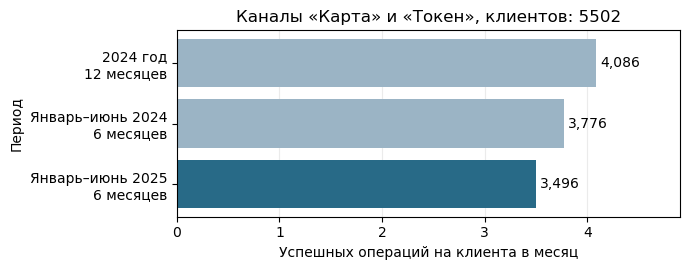

In [19]:
report_cohort_size = len(clean)

report_rates = pd.Series({
    "2024 год\n12 месяцев":
        len(report_base_ops) / report_cohort_size / 12,

    "Январь–июнь 2024\n6 месяцев":
        len(report_base_h1_ops) / report_cohort_size / 6,

    "Январь–июнь 2025\n6 месяцев":
        len(report_current_ops) / report_cohort_size / 6,
})

change_to_year = (
    report_rates.iloc[2] / report_rates.iloc[0] - 1
) * 100

change_to_same_months = (
    report_rates.iloc[2] / report_rates.iloc[1] - 1
) * 100

print(
    "Изменение к 2024 году:",
    f"{change_to_year:.2f}%".replace(".", ",")
)
print(
    "Изменение к тем же месяцам 2024 года:",
    f"{change_to_same_months:.2f}%".replace(".", ",")
)

fig, ax = plt.subplots(figsize=(7, 2.8))

bars = ax.barh(
    report_rates.index,
    report_rates.values,
    color=["#9BB4C5", "#9BB4C5", "#286A87"],
)

for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.04,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}".replace(".", ","),
        va="center",
    )

ax.invert_yaxis()
ax.set_xlim(0, report_rates.max() * 1.2)
ax.set_xlabel("Успешных операций на клиента в месяц")
ax.set_ylabel("Период")
ax.set_title(
    f"Каналы «Карта» и «Токен», клиентов: {report_cohort_size}"
)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

В когорте из 5502 клиентов среднее число успешных операций в каналах "Карта" и "Токен" снизилось с 4,086 на клиента в месяц за 2024 год до 3,496 за январь-июнь 2025 года.

Снижение сохраняется и при сравнении одинаковых месяцев: с 3,776 операции на клиента в месяц в первом полугодии 2024 года до 3,496 в первом полугодии 2025 года. Сравнение не устанавливает причины изменения. 

### 4.2. На массовый сегмент пришлось 90,31% общего чистого снижения   

Массовый сегмент: 2824 клиентов; изменение средней активности: -28,73%
Вклад массового сегмента: 2934,67 из 3249,42 операций в месяц; 90,31%
Массовый сегмент, одинаковые полугодия: 57278 в 43679 операций; -23,74%


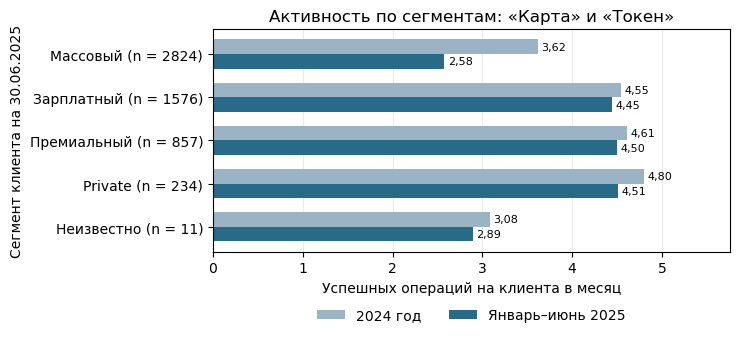

In [20]:
report_segment_data = clean[
    ["client_id", "segment", "operations_2024", "operations_2025_h1"]
].copy()

report_segment_data["segment_group"] = (
    report_segment_data["segment"]
    .astype("string")
    .fillna("Неизвестно")
)

report_h1_counts = report_base_h1_ops.groupby("client_id").size()

report_segment_data["operations_2024_h1"] = (
    report_segment_data["client_id"]
    .map(report_h1_counts)
    .fillna(0)
    .astype(int)
)

report_segments = report_segment_data.groupby(
    "segment_group", dropna=False
).agg(
    clients=("client_id", "size"),
    ops_2024=("operations_2024", "sum"),
    ops_2024_h1=("operations_2024_h1", "sum"),
    ops_2025_h1=("operations_2025_h1", "sum"),
).sort_values("clients", ascending=False)

report_segments["rate_2024"] = (
    report_segments["ops_2024"] / report_segments["clients"] / 12
)

report_segments["rate_2025_h1"] = (
    report_segments["ops_2025_h1"] / report_segments["clients"] / 6
)

report_segments["change_percent"] = (
    (
        report_segments["rate_2025_h1"]
        / report_segments["rate_2024"].where(
            report_segments["rate_2024"] != 0
        )
        - 1
    ) * 100
)

report_segments["monthly_drop"] = (
    report_segments["ops_2024"] / 12
    - report_segments["ops_2025_h1"] / 6
)

report_total_drop = report_segments["monthly_drop"].sum()

report_mass = report_segments.loc["Массовый"]

report_mass_share = (
    report_mass["monthly_drop"] / report_total_drop * 100
)

report_mass_same_months_change = (
    report_mass["ops_2025_h1"]
    / report_mass["ops_2024_h1"]
    - 1
) * 100

print(
    "Массовый сегмент:", int(report_mass["clients"]), "клиентов;",
    "изменение средней активности:",
    f"{report_mass['change_percent']:.2f}%".replace(".", ",")
)

print(
    "Вклад массового сегмента:",
    f"{report_mass['monthly_drop']:.2f}".replace(".", ","),
    "из",
    f"{report_total_drop:.2f}".replace(".", ","),
    "операций в месяц;",
    f"{report_mass_share:.2f}%".replace(".", ",")
)

print(
    "Массовый сегмент, одинаковые полугодия:",
    int(report_mass["ops_2024_h1"]), "в",
    int(report_mass["ops_2025_h1"]), "операций;",
    f"{report_mass_same_months_change:.2f}%".replace(".", ",")
)

positions = np.arange(len(report_segments))
height = 0.34

segment_labels = [
    str(segment) + " (n = " + str(int(row["clients"])) + ")"
    for segment, row in report_segments.iterrows()
]

fig, ax = plt.subplots(figsize=(7.5, 3.6))

bars_2024 = ax.barh(
    positions - height / 2,
    report_segments["rate_2024"],
    height=height,
    label="2024 год",
    color="#9BB4C5",
)

bars_2025 = ax.barh(
    positions + height / 2,
    report_segments["rate_2025_h1"],
    height=height,
    label="Январь–июнь 2025",
    color="#286A87",
)

for bars in [bars_2024, bars_2025]:
    for bar in bars:
        ax.text(
            bar.get_width() + 0.04,
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.2f}".replace(".", ","),
            va="center",
            fontsize=8,
        )

ax.set_yticks(positions)
ax.set_yticklabels(segment_labels)
ax.invert_yaxis()

max_rate = max(
    report_segments["rate_2024"].max(),
    report_segments["rate_2025_h1"].max(),
)
ax.set_xlim(0, max_rate * 1.2)

ax.set_xlabel("Успешных операций на клиента в месяц")
ax.set_ylabel("Сегмент клиента на 30.06.2025")
ax.set_title("Активность по сегментам: «Карта» и «Токен»")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=2,
    frameon=False,
)

plt.tight_layout()
plt.show()

В массовом сегменте 2824 клиента. Их средняя активность снизилась с 3,62 операции на клиента в месяц за 2024 год до 2,58 за первое полугодие 2025 года. 

На этот сегмент пришлось 2934,67 из 3249,42 операций в месяц общего чистого снижения по когорте. 

При сравнении одинаковых полугодий число выбранных операций массового сегмента снизилось с 57278 до 43679. Сегмент указан по состоянию на 30 июня 2025 года. 

### 4.3. Продукты и транспорт дали 46,1% снижения


Продукты: 844,42 операций в месяц; одинаковые полугодия: из 17035 в 13175 (-22,66%)
Транспорт: 508,50 операций в месяц; одинаковые полугодия: из 7477 в 4931 (-34,05%)
Вместе: 1352,92 из 2934,67 операций в месяц; 46,10%


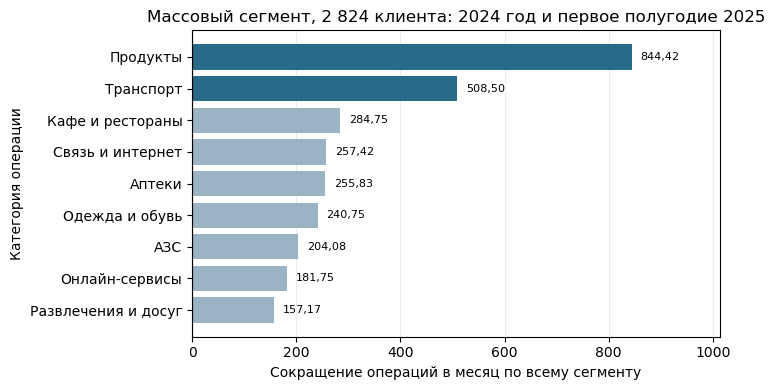

In [21]:
report_mass_ids = clean.loc[
    clean["segment"].eq("Массовый").fillna(False),
    "client_id",
]

if report_selected_ops["category"].isna().any():
    raise ValueError("В выбранных операциях есть пропуски категории.")

report_mass_base = report_base_ops.loc[
    report_base_ops["client_id"].isin(report_mass_ids)
]

report_mass_base_h1 = report_base_h1_ops.loc[
    report_base_h1_ops["client_id"].isin(report_mass_ids)
]

report_mass_current = report_current_ops.loc[
    report_current_ops["client_id"].isin(report_mass_ids)
]

report_mass_categories = pd.concat(
    [
        report_mass_base.groupby("category").size().rename("ops_2024"),
        report_mass_base_h1.groupby("category").size().rename("ops_2024_h1"),
        report_mass_current.groupby("category").size().rename("ops_2025_h1"),
    ],
    axis=1,
).fillna(0).astype(int)

report_mass_categories["monthly_drop"] = (
    report_mass_categories["ops_2024"] / 12
    - report_mass_categories["ops_2025_h1"] / 6
)

report_mass_categories["same_months_change"] = (
    (
        report_mass_categories["ops_2025_h1"]
        / report_mass_categories["ops_2024_h1"].where(
            report_mass_categories["ops_2024_h1"] != 0
        )
        - 1
    ) * 100
)

report_mass_categories = report_mass_categories.sort_values(
    "monthly_drop", ascending=False
)

report_mass_category_total = (
    report_mass_categories["monthly_drop"].sum()
)

if not np.isclose(
    report_mass_category_total,
    report_mass["monthly_drop"],
):
    raise ValueError(
        "Сумма изменений по категориям не совпала с итогом сегмента."
    )

report_food_transport_drop = (
    report_mass_categories.loc[
        ["Продукты", "Транспорт"], "monthly_drop"
    ].sum()
)

report_food_transport_share = (
    report_food_transport_drop / report_mass_category_total * 100
)

for category in ["Продукты", "Транспорт"]:
    row = report_mass_categories.loc[category]

    print(
        category + ":",
        f"{row['monthly_drop']:.2f}".replace(".", ","),
        "операций в месяц;",
        "одинаковые полугодия:", "из",
        int(row["ops_2024_h1"]), "в",
        int(row["ops_2025_h1"]),
        "(" + f"{row['same_months_change']:.2f}%".replace(".", ",") + ")",
    )

print(
    "Вместе:",
    f"{report_food_transport_drop:.2f}".replace(".", ","),
    "из",
    f"{report_mass_category_total:.2f}".replace(".", ","),
    "операций в месяц;",
    f"{report_food_transport_share:.2f}%".replace(".", ","),
)

colors = [
    "#286A87" if category in ["Продукты", "Транспорт"] else "#9BB4C5"
    for category in report_mass_categories.index
]

fig, ax = plt.subplots(figsize=(7.5, 4))

bars = ax.barh(
    report_mass_categories.index,
    report_mass_categories["monthly_drop"],
    color=colors,
)

minimum = min(0, report_mass_categories["monthly_drop"].min())
maximum = max(0, report_mass_categories["monthly_drop"].max())
span = max(maximum - minimum, 1)

for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.02 * span if value >= 0 else value - 0.02 * span,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}".replace(".", ","),
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=8,
    )

ax.invert_yaxis()
ax.set_xlim(
    minimum - 0.16 * span if minimum < 0 else 0,
    maximum + 0.2 * span,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Сокращение операций в месяц по всему сегменту")
ax.set_ylabel("Категория операции")
ax.set_title(
    "Массовый сегмент, 2 824 клиента: 2024 год и первое полугодие 2025"
)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Среди 2824 клиентов массового сегмента на продукты пришлось 844,42 операции в месяц чистого снижения, на транспорт - 508,5. Вместе это 1352,92 из 2934,67 операций в месяц общего снижения сегмента. 

При сравнении одинаковых полугодий число операций в продуктах снизилось с 17035 до 13175; в транспорте с 7477 до 4931. 

Показатели относятся ко всему массовому сегменту когорты, а не только к клиентам кампании. Один клиент может совершать операции в нескольких категориях. Категория показывает вклад в изменение числа операций, но не объесняет причину поведения. 

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->

Предлагается включить 1804 клиента в пять непересекающихся групп. 
Для всех групп действуют общие условия: клиент входит в сопоставимую когорту, дал согласие на маркетинговую коммуникацию, имел ненулевую активность в 2024 году и снизил среднее число операций в месяц. 
У каждого выбанного клиента есть единственная категория с наибольшим вкладом в снижение. 

В таблице активность указана на одного клиента в месяц. Вклад категории - это сокращение числа операций в месяц по всей группе, а не на одного клиента. 

Для понятности две группы названы по ведущей категории. В файле 'campaign_list.csv' им соответствуют технические метки "Все сегменты, транспорт" и "Все сегоменты, кафе и рестораны". Эти группы действительно смешаны по сегментам; их состав от переимеования в таблице не меняется. 

In [22]:
report_candidate_mask = (
    clean["marketing_opt_in"].eq("Да").fillna(False)
    & clean["operations_2024"].gt(0)
    & (2 * clean["operations_2025_h1"] < clean["operations_2024"])
)

report_candidates = clean.loc[report_candidate_mask].copy()

report_candidate_ids = pd.Index(
    report_candidates["client_id"],
    name="client_id",
)

report_categories = sorted(
    report_selected_ops["category"].dropna().unique()
)

report_category_base = (
    report_base_ops.groupby(["client_id", "category"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=report_candidate_ids,
        columns=report_categories,
        fill_value=0,
    )
)

report_category_current = (
    report_current_ops.groupby(["client_id", "category"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=report_candidate_ids,
        columns=report_categories,
        fill_value=0,
    )
)

report_category_loss_units = (
    report_category_base - 2 * report_category_current
)

report_candidates_by_id = (
    report_candidates.set_index("client_id")
    .reindex(report_candidate_ids)
)

report_expected_loss = (
    report_candidates_by_id["operations_2024"]
    - 2 * report_candidates_by_id["operations_2025_h1"]
)

if not np.array_equal(
    report_category_loss_units.sum(axis=1).to_numpy(),
    report_expected_loss.to_numpy(),
):
    raise ValueError(
        "Сумма вкладов категорий не совпала с активностью клиента."
    )

report_max_loss = report_category_loss_units.max(axis=1)

if not report_max_loss.gt(0).all():
    raise ValueError(
        "У одного из кандидатов не найден вклад категории в снижение."
    )

report_number_of_maxima = (
    report_category_loss_units.eq(report_max_loss, axis=0)
    .sum(axis=1)
)

report_candidates["leading_category"] = (
    report_candidates["client_id"]
    .map(report_category_loss_units.idxmax(axis=1))
)

report_candidates["leading_category_tie"] = (
    report_candidates["client_id"]
    .map(report_number_of_maxima.gt(1))
)

report_candidates["leading_drop_per_month"] = (
    report_candidates["client_id"].map(report_max_loss) / 12
)

report_campaign_clients = report_candidates.loc[
    report_candidates["group"].notna()
].copy()

if len(report_campaign_clients) != len(campaign_list):
    raise ValueError(
        "Не все клиенты кампании удовлетворяют общим условиям."
    )

if report_campaign_clients["leading_category_tie"].any():
    raise ValueError(
        "В кампании есть клиенты с равными ведущими категориями."
    )

report_expected_categories = {
    "Массовый, приложение, продукты": "Продукты",
    "Массовый, без приложения, продукты": "Продукты",
    "Все сегменты, транспорт": "Транспорт",
    "Зарплатный, продукты": "Продукты",
    "Все сегменты, кафе и рестораны": "Кафе и рестораны",
}

if set(report_campaign_clients["group"]) != set(report_expected_categories):
    raise ValueError("Обнаружены неожиданные названия групп.")

if not report_campaign_clients["leading_category"].eq(
    report_campaign_clients["group"].map(report_expected_categories)
).all():
    raise ValueError(
        "Ведущая категория не совпадает с правилом группы."
    )

if REPORT_DEBUG:
    print("Кандидатов со снижением и согласием:", len(report_candidates))
    print(
        "Из них с равными ведущими категориями:",
        report_candidates["leading_category_tie"].sum(),
    )
    print("Клиентов в пяти группах:", len(report_campaign_clients))
    print("Ведущие категории групп проверены.")

In [23]:
report_factor_overlap = report_candidates[["client_id"]].copy()

for report_field, report_value, report_name in [
    ("channel", "Карта", "card_decline"),
    ("category", "Продукты", "food_decline"),
]:
    report_factor_base = (
        report_base_ops.loc[report_base_ops[report_field].eq(report_value)]
        .groupby("client_id")
        .size()
    )

    report_factor_current = (
        report_current_ops.loc[
            report_current_ops[report_field].eq(report_value)
        ]
        .groupby("client_id")
        .size()
    )

    report_factor_base_count = (
        report_factor_overlap["client_id"]
        .map(report_factor_base)
        .fillna(0)
        .astype(int)
    )

    report_factor_current_count = (
        report_factor_overlap["client_id"]
        .map(report_factor_current)
        .fillna(0)
        .astype(int)
    )

    report_factor_overlap[report_name] = (
        report_factor_base_count.gt(0)
        & (2 * report_factor_current_count < report_factor_base_count)
    )

report_both_declined = (
    report_factor_overlap["card_decline"]
    & report_factor_overlap["food_decline"]
).sum()

report_candidate_count = len(report_factor_overlap)

if report_candidate_count == 0:
    raise ValueError("Нет кандидатов для расчёта пересечения.")

report_overlap_percent = (
    report_both_declined / report_candidate_count * 100
)

print(
    "Снижение по карте и продуктам одновременно:",
    report_both_declined,
    "из",
    report_candidate_count,
    "кандидатов —",
    f"{report_overlap_percent:.2f}%".replace(".", ","),
)

Снижение по карте и продуктам одновременно: 2114 из 2912 кандидатов — 72,60%


Снижение по каналу "Карта" в категории "Продукты" одновременно наблюдается у 2114 из 2912 клиентов со снижением общей активности и согласием на коммуникацию, то есть 72,6%. 

Эти разрезы пересекаются: одна операция может одновременно относиться к каналу "Карта" и категории "Продукты". Поэтому выбор ведущей категории для группы не означает, что другие составляющие активности у клиента не снижались. 

In [24]:
report_group_names = {
    "Массовый, приложение, продукты":
        "Массовый, приложение: продукты",
    "Массовый, без приложения, продукты":
        "Массовый, без приложения: продукты",
    "Все сегменты, транспорт":
        "Транспорт - ведущий вклад",
    "Зарплатный, продукты":
        "Зарплатный сегмент: продукты",
    "Все сегменты, кафе и рестораны":
        "Кафе и рестораны - ведущий вклад",
}

report_group_summary = (
    report_campaign_clients.groupby("group")
    .agg(
        clients=("client_id", "size"),
        ops_2024=("operations_2024", "sum"),
        ops_2025=("operations_2025_h1", "sum"),
        category=("leading_category", "first"),
        category_drop=("leading_drop_per_month", "sum"),
    )
    .reindex(report_expected_categories.keys())
)

report_group_summary["rate_2024"] = (
    report_group_summary["ops_2024"]
    / report_group_summary["clients"]
    / 12
)

report_group_summary["rate_2025"] = (
    report_group_summary["ops_2025"]
    / report_group_summary["clients"]
    / 6
)

report_group_summary["change_percent"] = (
    (
        report_group_summary["rate_2025"]
        / report_group_summary["rate_2024"].where(
            report_group_summary["rate_2024"] != 0
        )
        - 1
    ) * 100
)

report_group_table = report_group_summary[
    ["clients", "rate_2024", "rate_2025", "change_percent", "category_drop"]
].rename(
    index=report_group_names,
    columns={
        "clients": "Клиентов",
        "rate_2024": "2024",
        "rate_2025": "I п/г 2025",
        "change_percent": "Изменение, %",
        "category_drop": "Вклад категории, оп./мес.",
    },
)

report_group_table.index.name = "Группа"

display(report_group_table.round(2))

,Клиентов,2024,I п/г 2025,"Изменение, %","Вклад категории, оп./мес."
Группа,,,,,
"Массовый, приложение: продукты",465,4.38,2.21,-49.54,421.08
"Массовый, без приложения: продукты",370,4.17,1.64,-60.82,355.50
Транспорт - ведущий вклад,509,5.19,3.57,-31.17,533.33
Зарплатный сегмент: продукты,222,5.58,3.60,-35.42,201.42
Кафе и рестораны - ведущий вклад,238,5.34,3.83,-28.34,165.17


Массовый сегмент с приложением. Наибольший вклад в снижение пришелся на продукты. Можно проверить возможность предложения по этой категории через приложение. 
Массовый сегмент без приложения. Наибольший вклад также пришелся на продукты. Перед коммуникацией нужно проверить доступные способы связи с клиентами этой группы. 
Транспорт - ведущий вклад. Клиентов объединяет сокращение операций в категории "Транспорт". Группа включает представителей разных сегментов. 
Зарплатный сегмент. Наибольший вклад в снижение пришелся на операции в категории "Продукты". Можно рассмотреть предложение по этой категории для зарплатных клиентов. 
Кафе и рестораны - ведущий вклад. Это смешенная по сегментам группа клиентов, у которых наибольший вклад в снижение дали операции в кафе и ресторанах. 
Возможные предложения - гипотезы для проверки, а не установленныее причины снижения. Доступность конкретного канала связи и разрешение на его использование нужно проверить отдельно. 

## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->

Из 5502 клиентов сопоставимой когорты в кампанию не вошли 3698. В таблице каждому клиенту присвоена первая подходящая причина исключения, поэтому строки не пересекаются. Доли рассчитаны от всей когорты. 

In [25]:
report_exclusion = clean[
    [
        "client_id",
        "marketing_opt_in",
        "operations_2024",
        "operations_2025_h1",
        "group",
    ]
].copy()

report_tie_by_client = report_candidates.set_index(
    "client_id"
)["leading_category_tie"]

report_mapped_tie = (
    report_exclusion["client_id"]
    .map(report_tie_by_client)
    .astype("boolean")
)

report_is_candidate = report_exclusion["client_id"].isin(
    report_candidates["client_id"]
)

if report_mapped_tie[report_is_candidate].isna().any():
    raise ValueError(
        "Для некоторых кандидатов не найден признак равенства категорий."
    )

report_has_consent = (
    report_exclusion["marketing_opt_in"]
    .eq("Да")
    .fillna(False)
    .astype(bool)
)

report_base_count = report_exclusion["operations_2024"]
report_current_count = report_exclusion["operations_2025_h1"]
report_tie = report_mapped_tie.fillna(False).astype(bool)

report_reasons = [
    "Включён в кампанию",
    "Нет подтверждённого согласия",
    "Нет выбранных операций в обоих периодах",
    "Нет базы за 2024 год, но есть операции в 2025",
    "Активность выросла",
    "Активность не изменилась",
    "Несколько равных ведущих категорий",
    "Снижение есть, но вне правил пяти групп",
]

report_conditions = [
    report_exclusion["group"].notna(),

    ~report_has_consent,

    (report_base_count == 0) & (report_current_count == 0),

    (report_base_count == 0) & (report_current_count > 0),

    (report_base_count > 0)
    & (2 * report_current_count > report_base_count),

    (report_base_count > 0)
    & (2 * report_current_count == report_base_count),

    report_tie,

    (report_base_count > 0)
    & (2 * report_current_count < report_base_count),
]

report_exclusion["result"] = np.select(
    [condition.to_numpy(dtype=bool) for condition in report_conditions],
    report_reasons,
    default="Требует проверки",
)

if report_exclusion["result"].eq("Требует проверки").any():
    raise ValueError("Не для всех клиентов определена категория.")

if (
    report_exclusion["result"].eq("Включён в кампанию").sum()
    != len(campaign_list)
):
    raise ValueError("Число включённых клиентов не совпало с кампанией.")

report_exclusion_counts = (
    report_exclusion["result"]
    .value_counts()
    .reindex(report_reasons, fill_value=0)
)

report_excluded_counts = report_exclusion_counts.drop(
    "Включён в кампанию"
)

report_exclusion_table = pd.DataFrame({
    "Клиентов": report_excluded_counts,
    "Доля от когорты, %": report_excluded_counts / len(clean) * 100,
})

report_exclusion_table.index.name = "Причина исключения"

report_excluded_total = int(report_excluded_counts.sum())

if report_excluded_total != len(clean) - len(campaign_list):
    raise ValueError("Число исключённых клиентов не совпало с итогом.")

report_exclusion_total_row = pd.DataFrame(
    {
        "Клиентов": [report_excluded_total],
        "Доля от когорты, %": [
            report_excluded_total / len(clean) * 100
        ],
    },
    index=pd.Index(
        ["Итого не включено"],
        name="Причина исключения",
    ),
)

report_exclusion_table = pd.concat([
    report_exclusion_table,
    report_exclusion_total_row,
])

display(report_exclusion_table.round(2))

print(
    "Неиспользованный лимит кампании:",
    2000 - len(campaign_list),
    "клиентов",
)

,Клиентов,"Доля от когорты, %"
Причина исключения,,
Нет подтверждённого согласия,680,12.36
Нет выбранных операций в обоих периодах,26,0.47
"Нет базы за 2024 год, но есть операции в 2025",307,5.58
Активность выросла,1471,26.74
Активность не изменилась,106,1.93
Несколько равных ведущих категорий,418,7.60
"Снижение есть, но вне правил пяти групп",690,12.54
Итого не включено,3698,67.21


Неиспользованный лимит кампании: 196 клиентов


Клиентов без подтвержденного согласия включать нельзя. Если нет базы за 2024 год, относительное снижение определить невозможно. Отсутствие выбранных операций не означает отсутствия активности во всех каналах. Клиенты с ростом или неизменной активностью не соответствуют цели текущего отбора. 

При равных ведущих категориях нет основания выбирать одну из них произвольно. Клиенты со снижением, оставшиеся вне пяти правил, также могут нуждаться в коммуникации, но не входят в предложенные группы. Их исключение не объясняется исчерпанием бюджета: остается 196 мест. 

Еще 138 клиентов находятся вне сопоставимой когорты и не входят в приведенные выше 3698 человек. 

## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->

Ниже приведены четыре описательные проверки. Это не статистические тесты: они помогают уточнить выводы и выявить ограничения данных. 

In [26]:
def report_number(value, digits=0):
    """Формат числа для отчёта: пробелы в тысячах и десятичная запятая."""
    return f"{value:,.{digits}f}".replace(",", " ").replace(".", ",")


report_mass_token = report_successful.loc[
    report_successful["client_id"].isin(report_mass_ids)
    & report_successful["channel"].eq("Токен")
]

report_token_2024 = len(
    report_mass_token.loc[
        (report_mass_token["txn_datetime"] >= "2024-01-01")
        & (report_mass_token["txn_datetime"] < "2024-07-01")
    ]
)

report_token_2025 = len(
    report_mass_token.loc[
        (report_mass_token["txn_datetime"] >= "2025-01-01")
        & (report_mass_token["txn_datetime"] < "2025-07-01")
    ]
)

if report_token_2024 == 0:
    raise ValueError("Нет базы для сравнения операций по токену.")

report_token_change = (
    report_token_2025 / report_token_2024 - 1
) * 100

report_transport_2024 = int(
    report_mass_categories.loc["Транспорт", "ops_2024_h1"]
)

report_transport_2025 = int(
    report_mass_categories.loc["Транспорт", "ops_2025_h1"]
)

report_transport_change = report_mass_categories.loc[
    "Транспорт", "same_months_change"
]

report_mcc_compared_count = int(report_mcc_comparable.sum())
report_mcc_mismatch_count = int(report_mcc_disagreement.sum())

if report_mcc_compared_count == 0:
    raise ValueError("Нет операций для сравнения категории с MCC.")

report_mcc_mismatch_percent = (
    report_mcc_mismatch_count / report_mcc_compared_count * 100
)

report_hypotheses = pd.DataFrame([
    {
        "Гипотеза": "Снижение исчезает при сравнении одинаковых месяцев",
        "Период и охват":
            "I полугодия 2024 и 2025; "
            + report_number(len(clean)) + " клиентов",
        "Результат":
            " из " + report_number(report_rates.iloc[1], 3) + " в "
            + report_number(report_rates.iloc[2], 3)
            + " операций на клиента в месяц; "
            + report_number(change_to_same_months, 2) + "%",
    },
    {
        "Гипотеза": "В массовом сегменте снижаются все каналы",
        "Период и охват":
            "I полугодия 2024 и 2025; "
            + report_number(len(report_mass_ids)) + " клиентов",
        "Результат":
            "операции по токену: из "
            + report_number(report_token_2024) + " в "
            + report_number(report_token_2025)
            + "; изменение +" + report_number(report_token_change, 2) + "%",
    },
    {
        "Гипотеза": "В массовом сегменте снижение затрагивает только продукты",
        "Период и охват":
            "I полугодия 2024 и 2025; "
            + report_number(len(report_mass_ids)) + " клиентов",
        "Результат":
            "операции в транспорте: из "
            + report_number(report_transport_2024) + " в "
            + report_number(report_transport_2025)
            + "; изменение " + report_number(report_transport_change, 2) + "%",
    },
    {
        "Гипотеза": "Все категории совпадают с наиболее частой категорией MCC",
        "Период и охват":
            "2024 год — I полугодие 2025; "
            + report_number(report_mcc_compared_count) + " операций",
        "Результат":
            report_number(report_mcc_mismatch_count)
            + " расхождений, или "
            + report_number(report_mcc_mismatch_percent, 2) + "%",
    },
])

with pd.option_context("display.max_colwidth", None):
    display(report_hypotheses)

,Гипотеза,Период и охват,Результат
0,Снижение исчезает при сравнении одинаковых месяцев,I полугодия 2024 и 2025; 5 502 клиентов,"из 3,776 в 3,496 операций на клиента в месяц; -7,41%"
1,В массовом сегменте снижаются все каналы,I полугодия 2024 и 2025; 2 824 клиентов,"операции по токену: из 12 135 в 15 275; изменение +25,88%"
2,В массовом сегменте снижение затрагивает только продукты,I полугодия 2024 и 2025; 2 824 клиентов,"операции в транспорте: из 7 477 в 4 931; изменение -34,05%"
3,Все категории совпадают с наиболее частой категорией MCC,2024 год — I полугодие 2025; 385 214 операций,"1 066 расхождений, или 0,28%"


Все четыре предположения не подтвердились на этих данных. Наиболее частая категория МСС использована как эмпирический ориентир, а не официальный справочник: расхождение само по себе не доказывает ошибку операции. 

Рост числа операций в категории "Токен" также не доказывает, что те же клиенты перешли с пластиковой карты на оплату телефоном или часами. 

## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

В полном журнале 'cleaning_log.csv' зафиксировано 30 решений. Ниже приведины десять записей, отражающих основные обнаруженные проблемы и действия с данными, включая решения оставить значения без изменений. 
Числа относятся к разным полям и выборкам и могут пересекаться: их нельзя складывать. 

In [27]:
report_log_specs = [
    (
        "все поля clients",
        "полностью одинаковые строки клиентов",
    ),
    (
        "все поля transactions",
        "полностью одинаковые строки операций",
    ),
    (
        "txn_id, txn_datetime",
        "повторные операции с разной точностью даты и времени",
    ),
    (
        "client_id",
        "несколько различающихся записей одного клиента",
    ),
    (
        "city",
        "различающиеся города для одного client_id",
    ),
    (
        "segment",
        "различающиеся сегменты для одного client_id",
    ),
    (
        "category",
        "разные написания категорий операций",
    ),
    (
        "monthly_income",
        "отрицательное специальное значение -999",
    ),
    (
        "satisfaction_score",
        "отсутствует оценка удовлетворённости",
    ),
    (
        "amount",
        "кандидаты на выбросы по IQR отдельно по валютам",
    ),
]

report_log_rows = []

for report_log_field, report_log_issue in report_log_specs:
    report_log_match = cleaning_log.loc[
        cleaning_log["field"].eq(report_log_field)
        & cleaning_log["issue"].eq(report_log_issue)
    ]

    if len(report_log_match) != 1:
        raise ValueError(
            "Не удалось однозначно найти запись журнала: "
            + report_log_field + " — " + report_log_issue
        )

    report_log_rows.append(report_log_match.iloc[0])

report_log_summary = (
    pd.DataFrame(report_log_rows)[
        ["field", "issue", "n_rows", "action"]
    ]
    .rename(columns={
        "field": "Поле",
        "issue": "Что обнаружено",
        "n_rows": "Количество",
        "action": "Решение",
    })
    .reset_index(drop=True)
    .set_index("Поле")
)

print("Всего записей в полном журнале:", len(cleaning_log))
with pd.option_context("display.max_colwidth", None): 
    display(report_log_summary)

Всего записей в полном журнале: 30


,Что обнаружено,Количество,Решение
Поле,,,
все поля clients,полностью одинаковые строки клиентов,40,удалены повторные полные копии
все поля transactions,полностью одинаковые строки операций,1275,удалены повторные полные копии
"txn_id, txn_datetime",повторные операции с разной точностью даты и времени,225,удалена строка только с датой
client_id,несколько различающихся записей одного клиента,15,записи сведены к одной строке на client_id
city,различающиеся города для одного client_id,13,значение обозначено как неизвестное
segment,различающиеся сегменты для одного client_id,11,значение обозначено как неизвестное
category,разные написания категорий операций,51322,нормализация написаний
monthly_income,отрицательное специальное значение -999,47,заменено на пропуск
satisfaction_score,отсутствует оценка удовлетворённости,3379,оставлено без заполнения


### 8.2. Методика

<!-- Точные формулы, фильтры, пороги и их значения. Всё, что нужно,
     чтобы повторить расчёт. -->

Для сравнения используется когорта клиентов, зарегистрированных не позднее 1 января 2024 года и присутствующих в справочнике на 30 июня 2025 года. В метрику входят успешные операции этой когорты за 2024 год и январь–июнь 2025 года в каналах «Карта» и «Токен». Число операций считается независимо от валюты; суммы разных валют не складываются.

Для каждого клиента базовая активность равна числу операций за 2024 год, делённому на 12; текущая — числу операций за январь–июнь 2025 года, делённому на 6. При ненулевой базе снижение определяется условием: 

2 * число операций за январь-июнь 2025 < число операций за 2024 год. 

Для категории её вклад в снижение равен числу операций за 2024 год, делённому на 12, минус число операций за первое полугодие 2025 года, делённое на 6. Для отбора используется единственная категория с максимальным вкладом. При равенстве максимальных вкладов клиент не включается по этим правилам. Признаки пяти групп описаны в разделе 5. 

Для проверки сезонности отдельно сравнивались январь-июнь 2024 и январь-июнь 2025 года. Категория операции также сопоставлялась с наиболее частой категорией её MCC, рассчитанной по исходным операциям после объединения вариантов написания категорий. Это ориентир, а не официальный справочник; категории операций по нему не исправлялись. 

Кандидаты на выбросы определялись границами: 
Q1 - 1,5 * IQR и Q3 + 1,5 * IQR, где IQR = Q3 - Q1.
Для дохода границы рассчитывались по известным значениям очищенного справочника. Для сумм операций - отдельно по каждой валюте, среди успешных положительных операций за исследуемый период. Кандидаты были оставлены; проверка наличия значений в исходной выгрузке не подтверждает их истинность. Фильтр положительной суммы применялся
для исследования выбросов, но не для основной метрики активности.

In [28]:
report_outlier_ops = report_transactions.loc[
    (report_transactions["txn_datetime"] >= "2024-01-01")
    & (report_transactions["txn_datetime"] < "2025-07-01")
    & report_transactions["status"].eq("успешно")
    & report_transactions["amount"].gt(0)
].copy()

if report_outlier_ops["currency"].isna().any():
    raise ValueError("В выборке сумм есть операции без валюты.")

report_amount_by_currency = report_outlier_ops.groupby(
    "currency"
)["amount"]

report_amount_iqr = pd.DataFrame({
    "Операций": report_amount_by_currency.count(),
    "Q1": report_amount_by_currency.quantile(0.25),
    "Q3": report_amount_by_currency.quantile(0.75),
})

report_amount_iqr["Нижняя граница"] = (
    report_amount_iqr["Q1"]
    - 1.5 * (report_amount_iqr["Q3"] - report_amount_iqr["Q1"])
)

report_amount_iqr["Верхняя граница"] = (
    report_amount_iqr["Q3"]
    + 1.5 * (report_amount_iqr["Q3"] - report_amount_iqr["Q1"])
)

report_amount_lower = report_outlier_ops["currency"].map(
    report_amount_iqr["Нижняя граница"]
)

report_amount_upper = report_outlier_ops["currency"].map(
    report_amount_iqr["Верхняя граница"]
)

report_amount_candidates = (
    report_outlier_ops["amount"].lt(report_amount_lower)
    | report_outlier_ops["amount"].gt(report_amount_upper)
)

report_amount_iqr["Кандидатов"] = (
    report_outlier_ops.loc[report_amount_candidates]
    .groupby("currency")
    .size()
    .reindex(report_amount_iqr.index, fill_value=0)
)

report_amount_iqr.index.name = "Валюта"

report_income_iqr_log = cleaning_log.loc[
    cleaning_log["field"].eq("monthly_income")
    & cleaning_log["issue"].eq(
        "кандидаты на выбросы по общему правилу IQR"
    )
]

report_amount_iqr_log = cleaning_log.loc[
    cleaning_log["field"].eq("amount")
    & cleaning_log["issue"].eq(
        "кандидаты на выбросы по IQR отдельно по валютам"
    )
]

if len(report_income_iqr_log) != 1 or len(report_amount_iqr_log) != 1:
    raise ValueError("Не удалось найти решения по IQR в журнале.")

if (
    int(report_amount_iqr["Кандидатов"].sum())
    != int(report_amount_iqr_log["n_rows"].iloc[0])
):
    raise ValueError(
        "Число кандидатов по суммам не совпало с журналом."
    )

print(
    "Границы для дохода из журнала:",
    report_income_iqr_log["scope"].iloc[0],
)
print(
    "Кандидатов по доходу:",
    int(report_income_iqr_log["n_rows"].iloc[0]),
)

display(report_amount_iqr.round(2))

Границы для дохода из журнала: непропущенный доход ниже -33625.0 или выше 194975.0 руб.
Кандидатов по доходу: 420


,Операций,Q1,Q3,Нижняя граница,Верхняя граница,Кандидатов
Валюта,,,,,,
EUR,1234,4.42,24.63,-25.90,54.94,107
RUB,594351,469.62,2217.60,-2152.36,4839.58,47834
USD,1182,5.19,22.86,-21.31,49.37,93


### 8.3. Использование ИИ

<!-- 3–5 строк: для чего использовали и что проверили сами. -->

ИИ-ассистент помогал писать код расчетов. 
Мною были сверены расчеты, размеры групп, согласия, пересечения и проверка чувствительности, а также сформулированы выводы отчета. 